In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

inc = pd.read_csv("data/processed/incidents_geo.csv",
                  dtype={"station": str, "nearest_station": str, "neighbourhood_id": str},
                  parse_dates=["alarm", "arrival"])
inc.shape

/var/folders/98/p89mc3nd1d34f9jndy3v2lz00000gn/T/ipykernel_35569/1655364226.py:6: DtypeWarning: Columns (5: Incident_Station_Area) have mixed types. Specify dtype option on import or set low_memory=False.
  inc = pd.read_csv("data/processed/incidents_geo.csv",


(26168, 58)

In [3]:
print(inc["wait_s"].quantile([0.5, 0.75, 0.9, 0.95]).round(0))
print("mean:", round(inc["wait_s"].mean()))

0.50    304.0
0.75    366.0
0.90    435.0
0.95    492.0
Name: wait_s, dtype: float64
mean: 315


In [4]:
by_year = inc.groupby("year")["wait_s"].agg(n="size", median_s="median",
                                             p90_s=lambda s: s.quantile(0.9)).round(0)
by_year

,n,median_s,p90_s
year,,,
2011,1808,317.0,454.0
2012,1832,301.0,420.0
2013,1796,308.0,427.0
2014,1843,297.0,429.0
2015,1816,302.0,418.0
2016,1834,300.0,429.0
2017,1753,293.0,415.0
2018,1982,297.0,429.0
2019,1869,300.0,426.0


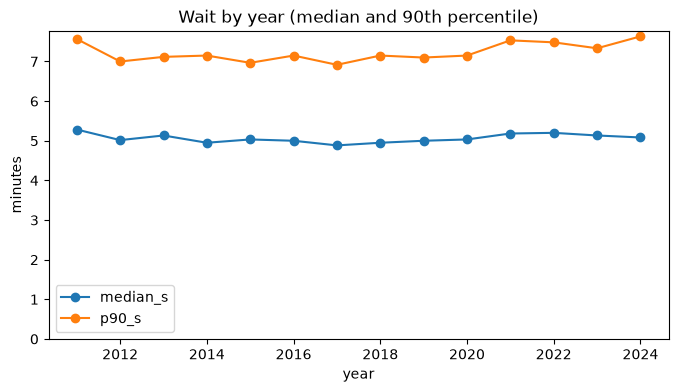

In [5]:
ax = (by_year[["median_s", "p90_s"]] / 60).plot(marker="o", figsize=(8, 4))
ax.set_ylim(0)
ax.set_ylabel("minutes")
ax.set_title("Wait by year (median and 90th percentile)")
plt.show()

In [6]:
inc.groupby("year")["dist_nearest_km"].median().round(2)

year
2011    0.95
2012    0.93
2013    0.94
2014    0.92
2015    0.97
2016    0.94
2017    0.96
2018    0.96
2019    0.98
2020    0.95
2021    0.96
2022    0.96
2023    0.98
2024    0.98
Name: dist_nearest_km, dtype: float64

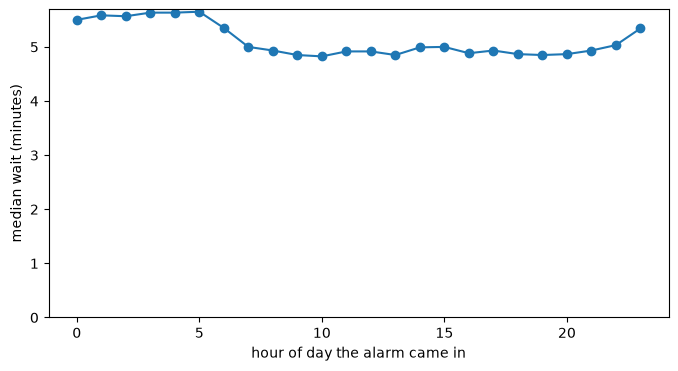

hour
0     5.50
1     5.58
2     5.57
3     5.63
4     5.63
5     5.65
6     5.35
7     5.00
8     4.93
9     4.85
10    4.82
11    4.92
12    4.92
13    4.85
14    4.99
15    5.00
16    4.88
17    4.93
18    4.87
19    4.85
20    4.87
21    4.93
22    5.03
23    5.34
Name: wait_s, dtype: float64

In [7]:
by_hour = inc.groupby("hour")["wait_s"].median() / 60
ax = by_hour.plot(marker="o", figsize=(8, 4))
ax.set_ylim(0)
ax.set_xlabel("hour of day the alarm came in")
ax.set_ylabel("median wait (minutes)")
plt.show()
by_hour.round(2)

In [8]:
order = ["night", "morning", "afternoon", "evening"]
print(inc.groupby("daypart")["wait_s"].agg(["count", "median"]).reindex(order).round(0))
print(inc.groupby("is_weekend")["wait_s"].median())

           count  median
daypart                 
night       4628   336.0
morning     5168   297.0
afternoon   8294   295.0
evening     8078   298.0
is_weekend
0    304.0
1    302.0
Name: wait_s, dtype: float64


In [9]:
nb = (inc.groupby(["neighbourhood_id", "neighbourhood_name"])
        .agg(n=("wait_s", "size"),
             median_s=("wait_s", "median"),
             p90_s=("wait_s", lambda s: s.quantile(0.9)),
             mean_dist_km=("dist_nearest_km", "mean"))
        .reset_index()
        .sort_values("median_s", ascending=False))
nb.head(10).round(1)

,neighbourhood_id,neighbourhood_name,n,median_s,p90_s,mean_dist_km
21,12,Markland Wood,60,411.0,492.8,2.0
43,144,Morningside Heights,300,399.0,697.1,1.8
82,23,Pelmo Park-Humberlea,200,391.5,520.4,1.8
109,5,Elms-Old Rexdale,110,389.0,485.4,1.7
50,150,Fenside-Parkwoods,150,388.5,483.2,1.5
62,161,Humber Bay Shores,93,387.0,511.8,1.8
104,44,Flemingdon Park,144,383.5,494.1,1.4
35,135,Morningside,162,381.0,469.9,1.6
46,147,L'Amoreaux West,87,369.0,462.4,1.8
32,130,Milliken,214,368.5,484.0,1.5


In [10]:
nb.tail(5).round(1)

,neighbourhood_id,neighbourhood_name,n,median_s,p90_s,mean_dist_km
68,167,Church-Wellesley,253,241.0,307.6,0.4
70,169,Bay-Cloverhill,111,239.0,304.0,0.3
134,73,Moss Park,493,237.0,312.8,0.5
133,72,Regent Park,127,230.0,294.0,0.5
135,74,North St.James Town,246,227.0,311.5,0.4


              median_s  mean_dist_km
median_s          1.00          0.86
mean_dist_km      0.86          1.00


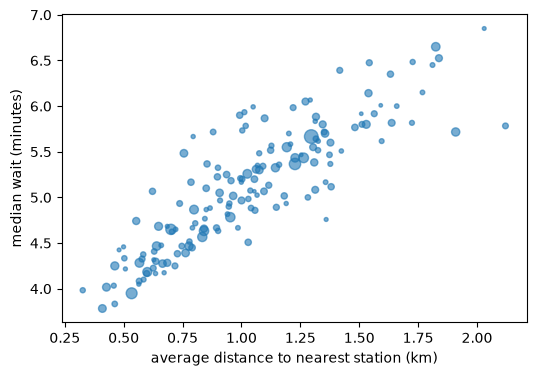

In [11]:
print(nb[["median_s", "mean_dist_km"]].corr(method="spearman").round(2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(nb["mean_dist_km"], nb["median_s"] / 60, s=nb["n"] / 8, alpha=0.6)
ax.set_xlabel("average distance to nearest station (km)")
ax.set_ylabel("median wait (minutes)")
plt.show()

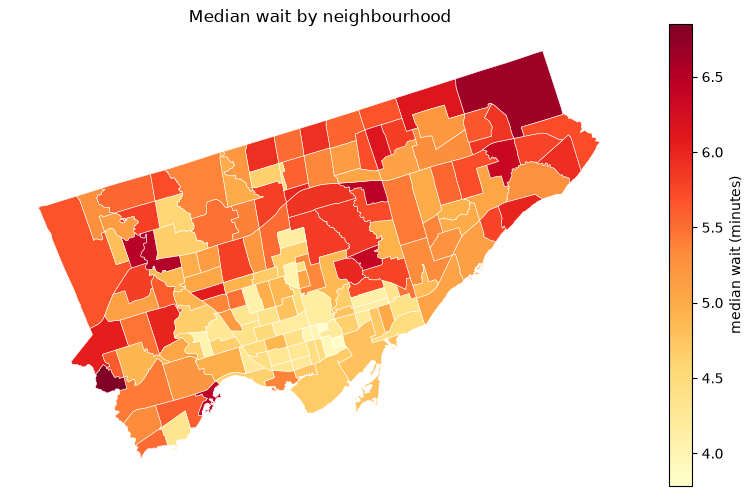

In [12]:
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

nbhd = pd.read_csv("data/raw/Neighbourhoods - 4326.csv")
lookup = nb.set_index("neighbourhood_id")["median_s"] / 60

def area(ring):
    x, y = np.array(ring).T
    return abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1))) / 2

items = []
for _, r in nbhd.iterrows():
    g = json.loads(r["geometry"])
    polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
    for poly in polys:
        items.append((area(poly[0]), np.array(poly[0]), lookup.get(str(r["AREA_SHORT_CODE"]), np.nan)))
items.sort(key=lambda t: -t[0])   # draw big shapes first, so small ones inside them stay visible

pc = PatchCollection([Polygon(p, closed=True) for _, p, _ in items],
                     cmap="YlOrRd", edgecolor="white", linewidth=0.4)
pc.set_array(np.array([v for _, _, v in items]))

fig, ax = plt.subplots(figsize=(10, 6))
ax.add_collection(pc)
ax.autoscale_view()
ax.set_aspect(1 / np.cos(np.radians(43.7)))
fig.colorbar(pc, label="median wait (minutes)")
ax.set_axis_off()
ax.set_title("Median wait by neighbourhood")
plt.show()

In [13]:
nb.to_csv("data/processed/neighbourhood_summary.csv", index=False)

# Stage 4 summary: describing the patterns

Before building any model, I just wanted to see what the data looks like when sliced a few different ways.

Across all 26,168 incidents, the typical wait is about 5 minutes (median 304 s), and nine in ten incidents get a truck in about 7 minutes 15 seconds or less (90th percentile 435 s).

By year, nothing dramatic happens. The median stays between 293 and 317 seconds and the 90th percentile between 415 and 458 seconds, with a slight rise after 2017. The median distance to the nearest station is flat too (0.92 to 0.98 km), so the incidents didn't drift farther from stations over time, and I see no sign of a recording change in the later years.

Time of day matters most. Alarms between midnight and 6 am wait about 5.5 to 5.65 minutes at the median, against about 4.8 to 5 minutes during the day, so the night median is about 40 seconds longer (336 s versus 295 to 298 s). Weekends make no difference (304 s on weekdays versus 302 s).

By neighbourhood, the slowest medians are in places like Markland Wood (411 s), Morningside Heights (399 s), Pelmo Park-Humberlea and Elms-Old Rexdale. The fastest are all downtown: North St. James Town (227 s), Regent Park, Moss Park, Bay-Cloverhill and Church-Wellesley. On the map, the downtown core is pale and the outskirts, especially the far northeast and southwest, are darker.

The most important thing I learned is that this neighbourhood ranking is mostly a distance ranking. A neighbourhood's median wait has a rank correlation of 0.86 with its average distance to the nearest station. The fastest neighbourhoods sit 0.3 to 0.5 km from a station and the slowest about 1.5 to 2 km away. So the slow list says more about where stations are than about how any one neighbourhood is served, and I can't call a neighbourhood "underserved" from raw medians alone.

Two cautions. Small neighbourhoods are noisy: Markland Wood tops the slow list on only 60 incidents, so its rank could shift with a few more. And a median hides the long tail: Morningside Heights has a 90th percentile of 697 s (nearly 11.6 minutes), the longest on the list. Next I'll adjust for distance and for the other factors, and give the small neighbourhoods less weight, to see which places are slower than their distance explains.
## Some Important Points
**The neighbourhood median mostly track distance** because distance is a big part of the wait, so far-away neighbourhoods are slow almost by construction.  

**A median from 60 incidents less trustworthy than one from 700** because a few unusual incidents can swing it, so part of the ranking is luck.